# PMAR demo

**PMAR** (Particle-based Modelling and Analysis for MARine Decision Support) drives [OpenDrift](https://opendrift.github.io/)
to simulate Lagrangian particle trajectories representing different tracers (generic, plastic,
chemical, oil, metal or larvae), then derives:

- **geospatial indicators** (density maps, Pressure Propagation Index or PPI)
- a **connectivity matrix** describing transition probabilities between grid cells,

from those trajectories.

This notebook walks through the core workflow in four steps:

1. **Basic run** — simulate trajectories with `get_trajectories`.
2. **Rasterizing pressure** — turn trajectories into gridded indicators with `get_indicators` and `get_ppi`.
3. **Connectivity analysis** — build a connectivity matrix and network with `get_cm` and `get_network`.
4. **Markov-chain prediction** — propagate a distribution forward in time with `predict_with_cm`.

**Requirements**: run this notebook with the `opendrift` conda environment as the kernel
(it provides OpenDrift, PMAR's other geospatial dependencies, and has `PROJ_LIB` set up
correctly). You'll also need working Copernicus Marine credentials in `~/.netrc` — the
first run streams a couple of days of Mediterranean current data; after that, PMAR's
on-disk cache makes re-running this notebook instant and fully offline.

In [1]:
from shapely.geometry import box
import geopandas as gpd
import matplotlib.pyplot as plt

from pmar.pmar import PMAR
from pmar import plotting
from pmar.utils import list_emodnet_uses, get_emodnet_use
# Small area in the Northern Adriatic Sea, and a single grid resolution, used
# throughout this notebook. Keeping one resolution everywhere means every raster
# we compute lives on exactly the same grid as the connectivity matrix, so they can be
# fed into each other directly with no resampling.
study_area = [12, 43.5, 16, 45.8]  # [xmin, ymin, xmax, ymax]
res = 0.1

## 1. Basic run: `get_trajectories`

A `PMAR` instance is tied to a spatial domain (one of `'global'`, `'med'`, `'black sea'`,
`'baltic'`) that determines which Copernicus datasets (currents, wind, bathymetry, ...)
are used to force the simulation. All outputs (cached trajectories, rasters, figures) are
written under `basedir`.

`get_trajectories` takes:

- `pnum` — number of particles to seed.
- `start_time` — simulation start date, as an ISO `'YYYY-MM-DD'` string.
- `duration_days` — length of the simulation.
- `seed_within_bounds` — `[xmin, ymin, xmax, ymax]` box to seed particles within (as an
  alternative to `seeding_shapefile`, for seeding from an arbitrary polygon/point/line
  shapefile instead of a rectangle).

We keep `pnum` and `duration_days` small here so the demo runs quickly.

In [2]:
p = PMAR(basedir='pmar_demo_output', loglevel=20)

2026-10-07 14:14:05,207 INFO    pmar:240: initializing pressure generic with opendrift module <class 'opendrift.models.oceandrift.OceanDrift'>


In [3]:
p.study_area = study_area  # reused by several methods below

params = {
    'pnum':1000,
    'start_time':'2021-06-01',
    'duration_days':10,
    'seed_within_bounds':study_area,
}

string


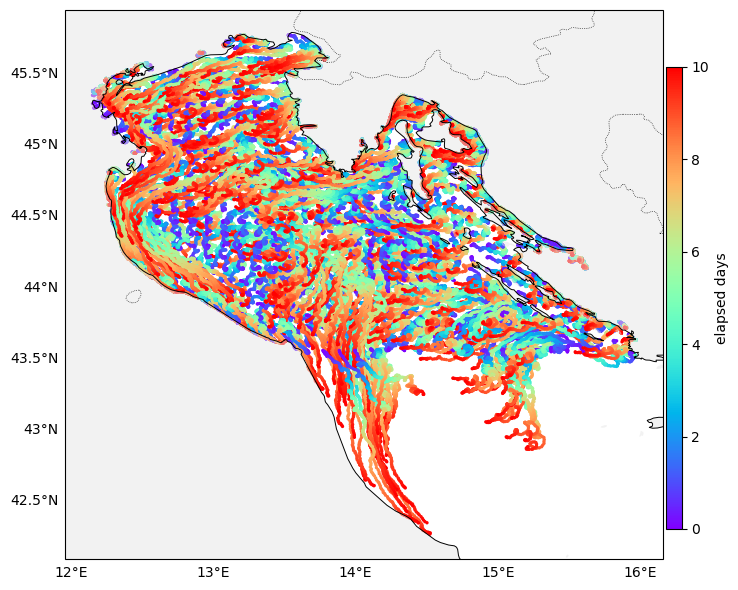

In [4]:
# p.get_trajectories(**params)

p.import_trajectories('pmar_demo_output/cachedir/08408fa4e4e37179c6727af9f6bdb25c.nc')
p.plot_trajectories(c='age', s=2)

## 2. Rasterizing pressure: `get_indicators` and `get_ppi`

Trajectories can be turned into gridded rasters in two complementary ways, both stored
together in `p.output`:

- **`get_indicators`** bins the raw (unweighted) particle positions over time into
  summary rasters: `SUM` (total visits per cell), `MAX` (peak concentration), and a
  quantile (`Q90` by default). This answers "where did particles actually go?".
- **`get_ppi`** computes the *Potential Pressure Index*: each particle is weighted by
  the intensity of a human-activity ("use") layer at its *starting* position, so the
  resulting raster answers "how much pressure, originating from this activity, reaches
  each cell?".

Instead of building a `use` layer by hand, we browse real human-activity datasets from the
[EMODnet Human Activities](https://emodnet.ec.europa.eu/en/human-activities) portal with
`list_emodnet_uses(study_area)`, which lists every WFS (vector) / WCS (raster) dataset
("use") available within our study area — its `name` column is exactly what `get_ppi`'s
`use=` argument expects. We pick `'emodnet__routedensity_allavg'` (a WCS raster of
shipping route density, averaged across all ship types) and pass its name straight to
`get_ppi`: a string `use` is recognised (inside `set_weights`) as an EMODnet dataset
identifier and fetched automatically, clipped to `study_area`.

In [5]:
p.get_indicators(res=res, study_area=study_area)

In [6]:
list_emodnet_uses(study_area)

                                   name                                                                                   title service output_type
           emodnet__routedensity_allavg                                          Route Density (EMSA) Annual Totals - All types     WCS      raster
            emodnet__routedensity_01avg                                              Route Density (EMSA) Annual Totals - Cargo     WCS      raster
            emodnet__routedensity_02avg                                            Route Density (EMSA) Annual Totals - Fishing     WCS      raster
            emodnet__routedensity_05avg                                              Route Density (EMSA) Annual Totals - Other     WCS      raster
            emodnet__routedensity_03avg                                          Route Density (EMSA) Annual Totals - Passenger     WCS      raster
            emodnet__routedensity_04avg                                             Route Density (EMSA) Annual 

,name,title,service,output_type
0,emodnet__routedensity_allavg,Route Density (EMSA) Annual Totals - All types,WCS,raster
1,emodnet__routedensity_01avg,Route Density (EMSA) Annual Totals - Cargo,WCS,raster
2,emodnet__routedensity_02avg,Route Density (EMSA) Annual Totals - Fishing,WCS,raster
3,emodnet__routedensity_05avg,Route Density (EMSA) Annual Totals - Other,WCS,raster
4,emodnet__routedensity_03avg,Route Density (EMSA) Annual Totals - Passenger,WCS,raster
...,...,...,...,...
139,emodnet:treatmentplants,Treatment Plants,WFS,vector
140,emodnet:unescowhl,UNESCO World Heritage Convention,WFS,vector
141,emodnet:wasteatports,Waste at Ports (m3/tonnes),WFS,vector
142,emodnet:windfarms,Wind Farms (Points),WFS,vector


2026-10-07 14:14:25,540 INFO    pmar:1156: ppi_exists = True, pmar_demo_output/ppi-emodnet__routedensity_allavg/f69d94b70409c9460f92018c00f825bd.tif


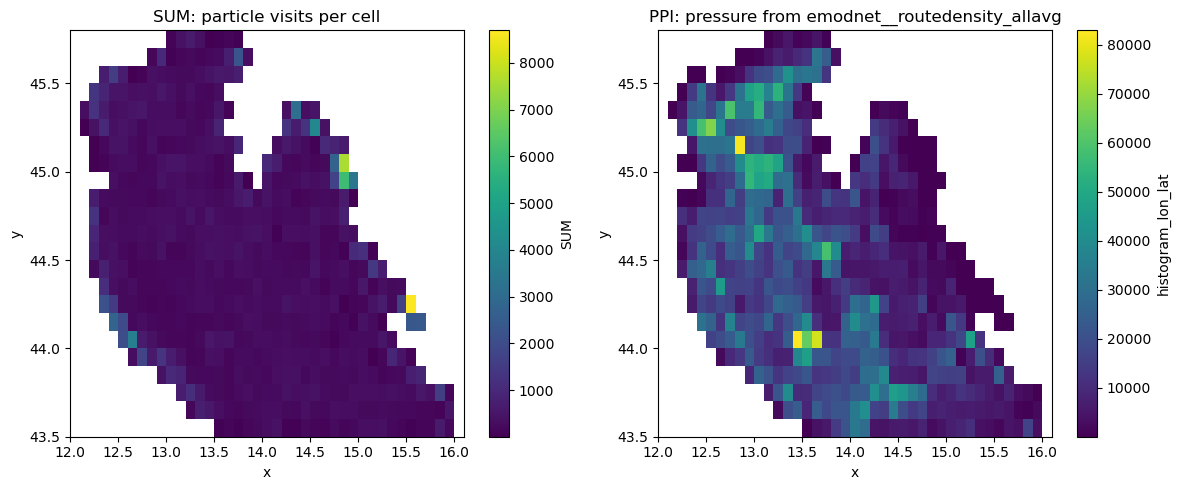

In [7]:
use_name = 'emodnet__routedensity_allavg'
p.duration = params['duration_days']
p.get_ppi(res=res, study_area=study_area, use=use_name, use_label=use_name)

fig, axs = plt.subplots(1, 2, figsize=(12, 5))
p.output['SUM'].where(p.output['SUM'] > 0).plot(ax=axs[0])
axs[0].set_title('SUM: particle visits per cell')
p.output['ppi'].where(p.output['ppi'] > 0).plot(ax=axs[1])
axs[1].set_title(f'PPI: pressure from {use_name}')
plt.tight_layout()

## 3. Connectivity analysis: `get_cm` and `get_network`

`get_cm` turns particle transitions into a Markov **transition matrix**: entry `(i, j)`
is the probability that a particle starting in cell `i` at `t=0` ends up in cell `j` at
timestep `t`. We reuse the same `res`/`study_area` as above, so the resulting grid of
cells matches the rasters from section 2 exactly — useful later when we feed one of those
rasters into the Markov prediction in section 4.

> **Note:** `get_cm` also accepts a `buffer` distance, which adds an absorbing
> "outside the tracked domain" cell — useful when the study area has open boundaries and
> you want particles that leave it to be treated as permanently gone rather than
> producing row sums below 1. Not used here, to keep the demo simple.

`get_network` turns the same matrix into a directed `networkx` graph, which we can then
draw. Cell boundaries (from `node_shapes`) give the plot spatial context even without a
full coastline basemap (`show_map=True` currently errors here when combined with the
default weight-based edge colorbar, due to a cartopy/matplotlib axes incompatibility in
`_plot_network` — using `show_map=False` avoids it). With this many cells we skip
`node_names` (per-node text labels) to keep the plot legible — labelling is more useful
on a much smaller network, e.g. `p.get_network(node_names=p.cm_grid['bin_n'].to_dict())`.

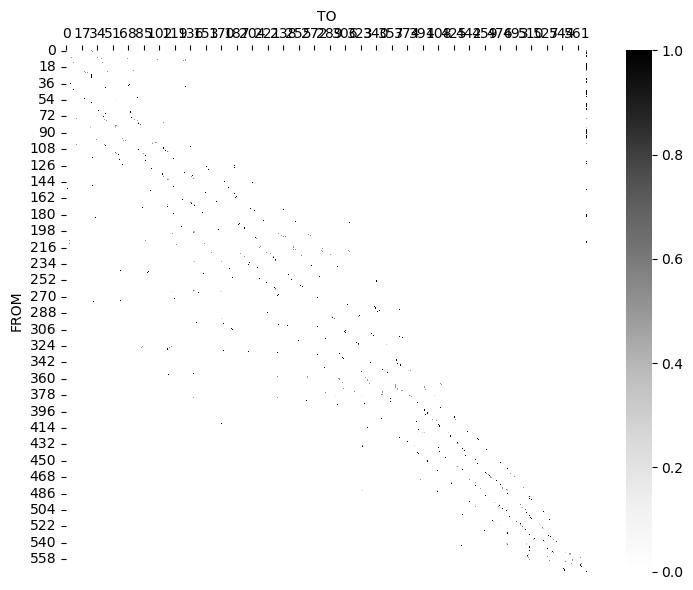

In [8]:
p.get_cm(res=res, study_area=study_area, t=-1, buffer=10)
p.plot_cm()

In [9]:
G = p.get_network()

((<Figure size 700x700 with 2 Axes>, <Axes: >),)

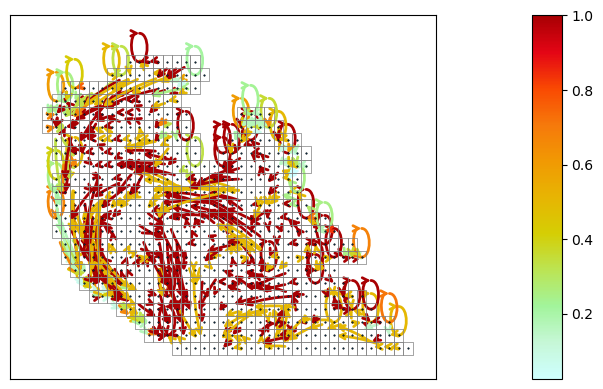

In [10]:
plotting._plot_network(
    G,
    node_shapes=p.cm_grid[:-1],
    show_map=False,
    node_size=1,
 #   rescale_edge=0.05
),  

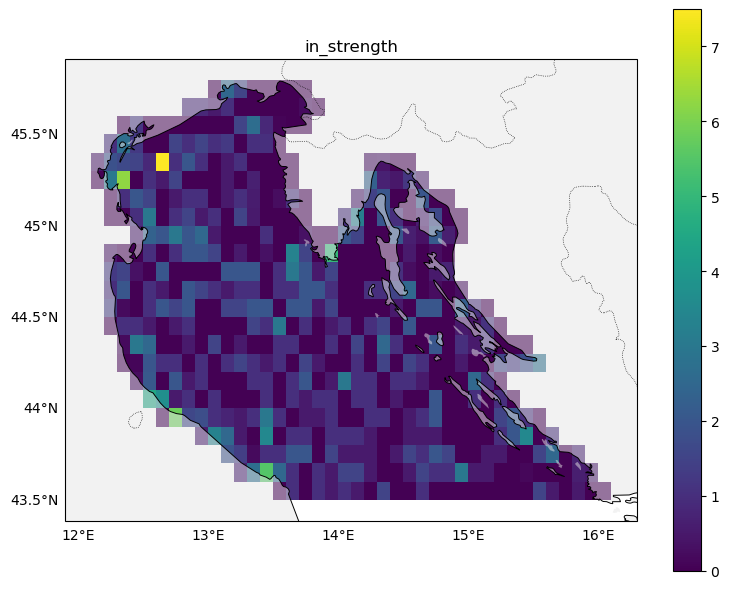

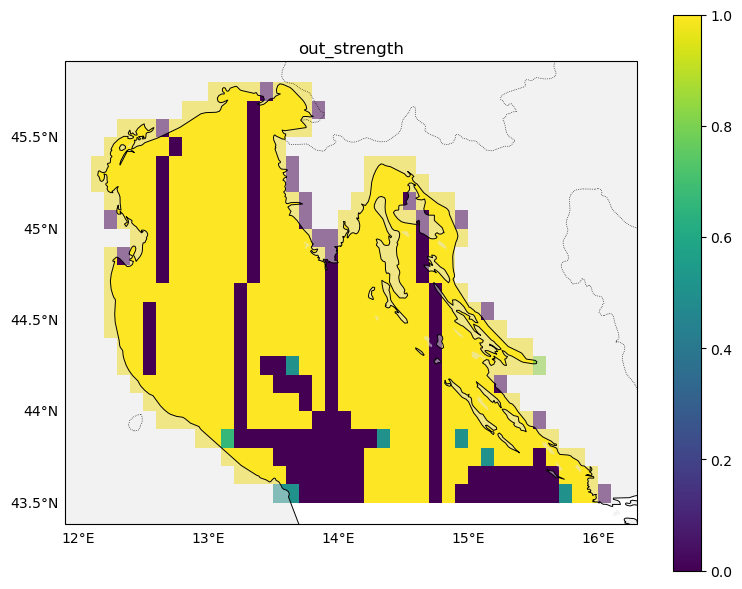

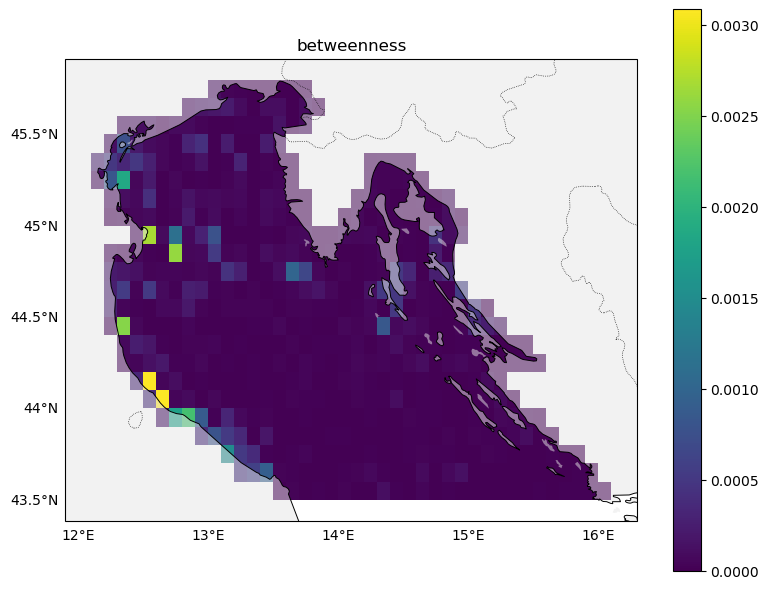

In [11]:
cdf = p.connectivity_analysis(plot=True)

## 4. Markov-chain prediction: `predict_with_cm`

Given a starting distribution (occupancy/probability per cell) and the transition matrix
`cm`, `predict_with_cm` propagates it forward `k` Markov steps: `v -> v @ cm^k`. Each step
corresponds to the same `t` used when the matrix was built (here, the full 2-day
transition from the basic run).

We reuse the `SUM` raster from section 2 as the starting distribution. `predict_with_cm`
reprojects its input onto whichever grid is currently set on `p.grid` — since we've used
the same `res`/`study_area` throughout, that's the same grid `SUM` was already computed
on, so this reprojection is effectively a no-op (important: feeding in a raster from a
*different* resolution than the connectivity matrix would silently distort results, since
reprojecting an additive quantity like a particle count onto a coarser grid via
nearest-neighbour resampling does not sum the finer cells it replaces).

2026-10-07 13:56:09,767 WARNING pmar:1736: initial_condition and cm dimensions do not match


(571,)
(571,)
148013.27393458676
Starting mass: 233706.0
Predicted mass: 148013.27393458676 (may be <= starting mass: some probability can leak outside the tracked domain)


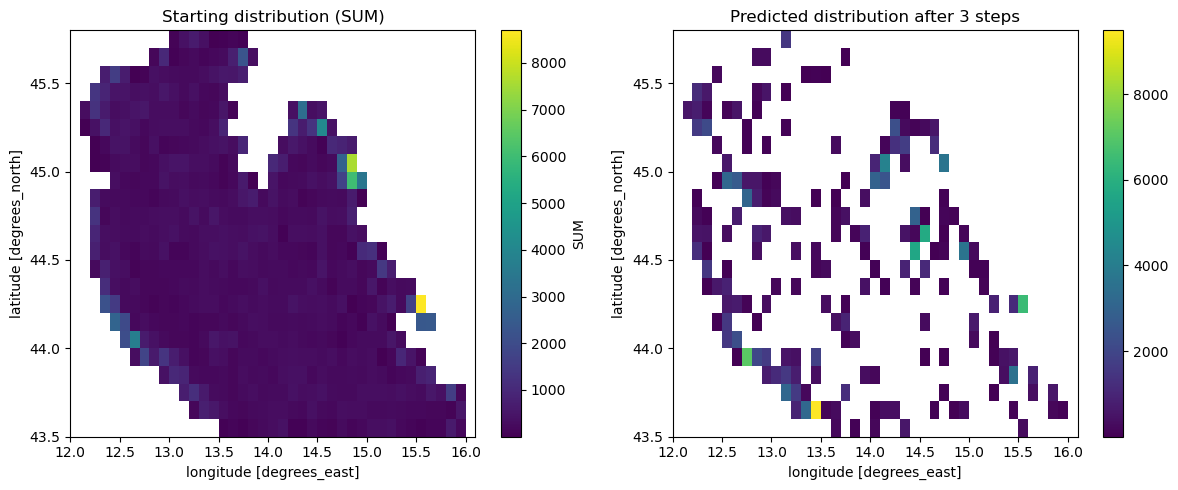

In [16]:
pred = p.predict_with_cm(p.output['SUM'], k=3)

fig, axs = plt.subplots(1, 2, figsize=(12, 5))
p.output['SUM'].where(p.output['SUM'] > 0).plot(ax=axs[0])
axs[0].set_title('Starting distribution (SUM)')
pred.where(pred > 0).plot(ax=axs[1])
axs[1].set_title('Predicted distribution after 3 steps')
plt.tight_layout()

print('Starting mass:', float(p.output['SUM'].sum()))
print('Predicted mass:', float(pred.sum()), '(may be <= starting mass: some probability can leak outside the tracked domain)')

## Where to go next

This notebook covered the core single-seeding workflow. A few other things PMAR can do:

- **Other pressure types**: pass `pressure='plastic'|'chemical'|'oil'|'metal'|'larvae'`
  to `PMAR(...)` instead of the default `'generic'` to use OpenDrift's specialized
  modules (e.g. `chemical_compound=` for `'chemical'`/`'metal'`).
- **Repeated seedings**: `PMARmulti` runs multiple seedings (e.g. at different start
  times) and averages results across them — useful for building a connectivity matrix
  that isn't tied to a single release date.
- **Dispersal distance**: `p.dispersal_distance()` computes the probability-weighted
  mean distance travelled from each cell, directly from the connectivity matrix.
- **`PMAR.run(...)`** bundles `get_trajectories` + `get_ppi` + `get_indicators` into a
  single call, for when you don't need the intermediate steps shown here.